# Xception Deepfake Detection with ART FGSM Adversarial Training

**Revised notebook:** preserves the uploaded dataset discovery and preprocessing design while fixing ART setup, repeated path scanning, duplicate model initialization, benchmark weight changes, memory use during clean/adversarial backward passes, and attack-time BatchNorm updates.

Run from top to bottom in Kaggle. A complete training run has not been verified in this environment; first run the short benchmark and inspect its estimate before committing to all epochs. Test data is only used in the final evaluation/visualization cells.

In [1]:
# [FIX] Install ART before importing the rest of the ML stack.
# Kaggle Internet must be enabled if ART is not already installed.
import importlib.util, subprocess, sys
if importlib.util.find_spec("art") is None:
    print("ART not found; installing adversarial-robustness-toolbox...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "adversarial-robustness-toolbox"])
else:
    print("ART is already installed.")


ART not found; installing adversarial-robustness-toolbox...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 15.0 MB/s eta 0:00:00


In [2]:
import os
import glob
import random
import cv2
import numpy as np
from PIL import Image
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import timm
import time, csv, copy, warnings

# Reproducibility (cuDNN benchmark is enabled later for throughput).
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


In [3]:
# 1. Device setup
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


In [4]:

import art
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import FastGradientMethod

print("ART imported successfully")
print("ART version:", getattr(art, "__version__", "unknown"))


ART imported successfully
ART version: 1.20.1


In [5]:

# Gentler Social Media Compression Function
def apply_social_media_compression(img_bgr):
    """
    Simulates moderate social-media compression:
    Mild Downscale -> Upscale -> Optional Gaussian Blur
    -> JPEG Compression -> RGB
    """
    h, w, _ = img_bgr.shape

    # Step 1: Mild downscaling and upscaling
    scale_factor = random.uniform(0.9, 1.0)

    new_h = max(1, int(h * scale_factor))
    new_w = max(1, int(w * scale_factor))

    img_resized = cv2.resize(
        img_bgr,
        (new_w, new_h),
        interpolation=cv2.INTER_AREA
    )

    img_resized = cv2.resize(
        img_resized,
        (w, h),
        interpolation=cv2.INTER_LINEAR
    )

    # Step 2: Optional mild Gaussian blur
    if random.random() < 0.2:
        img_resized = cv2.GaussianBlur(
            img_resized,
            (3, 3),
            0
        )

    # Step 3: Moderate JPEG compression
    quality = random.randint(40, 85)

    encode_param = [
        int(cv2.IMWRITE_JPEG_QUALITY),
        quality
    ]

    success, encimg = cv2.imencode(
        ".jpg",
        img_resized,
        encode_param
    )

    if not success:
        return cv2.cvtColor(
            img_bgr,
            cv2.COLOR_BGR2RGB
        )

    decimg_bgr = cv2.imdecode(
        encimg,
        cv2.IMREAD_COLOR
    )

    if decimg_bgr is None:
        return cv2.cvtColor(
            img_bgr,
            cv2.COLOR_BGR2RGB
        )

    # Step 4: Convert BGR to RGB
    return cv2.cvtColor(
        decimg_bgr,
        cv2.COLOR_BGR2RGB
    )


In [6]:

# [FIX] Dataset discovery is cached; folder and image-extension matching is case-insensitive.
class BalancedDeepfakeDataset(Dataset):
    _path_cache = {}

    def __init__(
        self,
        split='train',
        base_dir='/kaggle/input',
        transform=None,
        seed=42,
        compression_prob=0.5
    ):
        self.transform = transform
        self.compression_prob = compression_prob
        self.image_paths, self.labels = [], []
        self.rng = random.Random(seed)

        self._temp_data = {
            'celeb': {0: [], 1: []},
            '140k': {0: [], 1: []},
            'ffpp': {0: [], 1: []}
        }

        print(f"[{split.upper()}] Discovering datasets under {base_dir}...")
        dataset_paths = self._auto_discover_paths(base_dir)
        print(f"[{split.upper()}] Dataset roots: {dataset_paths}")

        self._load_celebdf(dataset_paths['celeb'], split)
        self._load_140k(dataset_paths['140k'], split)
        self._load_ffpp(dataset_paths['ffpp'], split)
        self._balance_and_merge(split)

    def _auto_discover_paths(self, base_dir):
        key = os.path.abspath(base_dir)

        if key in self._path_cache:
            print(f"Using cached dataset discovery for {base_dir}")
            return self._path_cache[key].copy()

        paths = {'celeb': None, 'ffpp': None, '140k': None}

        wanted = {
            'celeb_v2': 'celeb',
            'dataset_processed_split': 'ffpp',
            'real-vs-fake': '140k'
        }

        for root, dirs, files in os.walk(base_dir):
            lower_to_original = {d.lower(): d for d in dirs}

            for dirname, key_name in wanted.items():
                if (
                    paths[key_name] is None
                    and dirname in lower_to_original
                ):
                    paths[key_name] = os.path.join(
                        root, lower_to_original[dirname]
                    )

            if all(paths.values()):
                break

        self._path_cache[key] = paths.copy()
        return paths

    @staticmethod
    def _child_dir(parent, candidates):
        if not parent or not os.path.isdir(parent):
            return None

        lookup = {
            name.lower(): name
            for name in os.listdir(parent)
            if os.path.isdir(os.path.join(parent, name))
        }

        for candidate in candidates:
            if candidate.lower() in lookup:
                return os.path.join(parent, lookup[candidate.lower()])

        return None

    def _add_from_folder(self, dataset_name, folder_path, label):
        if folder_path and os.path.isdir(folder_path):
            valid_ext = {'.png', '.jpg', '.jpeg', '.webp', '.bmp'}

            try:
                for entry in os.scandir(folder_path):
                    if (
                        entry.is_file()
                        and os.path.splitext(entry.name)[1].lower() in valid_ext
                    ):
                        self._temp_data[dataset_name][label].append(
                            entry.path
                        )
            except OSError as exc:
                print(f"Warning: could not scan {folder_path}: {exc}")

    def _load_celebdf(self, base_path, split):
        split_map = {
            'train': ('Train', 'train'),
            'val': ('Val', 'val', 'valid'),
            'test': ('Test', 'test')
        }

        split_path = self._child_dir(
            base_path, split_map.get(split, ())
        )

        if not split_path:
            print(f"[{split.upper()}] Celeb-DF split not found.")
            return

        real_dir = self._child_dir(
            split_path, ('real', 'original', 'authentic')
        )
        fake_dir = self._child_dir(
            split_path, ('fake', 'manipulated', 'deepfake')
        )

        self._add_from_folder('celeb', real_dir, 0)
        self._add_from_folder('celeb', fake_dir, 1)

    def _load_140k(self, base_path, split):
        split_map = {
            'train': ('train',),
            'val': ('valid', 'val', 'validation'),
            'test': ('test',)
        }

        split_path = self._child_dir(
            base_path, split_map.get(split, ())
        )

        if not split_path:
            print(f"[{split.upper()}] 140K split not found.")
            return

        real_dir = self._child_dir(
            split_path, ('real', 'real_images', 'original')
        )
        fake_dir = self._child_dir(
            split_path, ('fake', 'fake_images', 'generated')
        )

        self._add_from_folder('140k', real_dir, 0)
        self._add_from_folder('140k', fake_dir, 1)

    def _load_ffpp(self, base_path, split):
        # Support common validation split names.
        split_candidates = {
            'train': ('train',),
            'val': ('val', 'valid', 'validation'),
            'test': ('test',)
        }

        split_path = self._child_dir(
            base_path, split_candidates.get(split, (split,))
        )

        if not split_path:
            print(
                f"[{split.upper()}] FFPP split not found: {base_path}"
            )
            return

        # Explicitly recognized authentic/original image folders.
        real_names = {
            'real',
            'original',
            'authentic',
            'real_videos',
            'original_sequences'
        }

        # FFPP manipulation-method folders.
        fake_names = {
            'fake',
            'manipulated',
            'deepfake',
            'fake_videos',
            'manipulated_sequences',
            'face2face',
            'deepfakes',
            'deepfakedetection',
            'neuraltextures',
            'faceshifter',
            'faceswap'
        }

        for class_dir in os.listdir(split_path):
            dir_path = os.path.join(split_path, class_dir)

            if not os.path.isdir(dir_path):
                continue

            name = class_dir.strip().lower()

            if name in real_names:
                label = 0
            elif name in fake_names:
                label = 1
            else:
                print(
                    f"[{split.upper()}] Skipping unrecognized "
                    f"FFPP folder: {class_dir!r}"
                )
                continue

            self._add_from_folder('ffpp', dir_path, label)

        print(
            f"[{split.upper()}] FFPP images collected: "
            f"real={len(self._temp_data['ffpp'][0])}, "
            f"fake={len(self._temp_data['ffpp'][1])}"
        )

    def _balance_and_merge(self, split):
        available = {}

        for ds_name, labels in self._temp_data.items():
            n_real = len(labels[0])
            n_fake = len(labels[1])

            if n_real and n_fake:
                available[ds_name] = labels
            else:
                print(
                    f"[{split.upper()}] Skipping {ds_name}: "
                    f"real={n_real}, fake={n_fake} "
                    f"(both classes required)."
                )

        if not available:
            raise RuntimeError(
                f"No usable dataset sources found for split={split!r}; "
                "check dataset roots and class folder names."
            )

        min_count = min(
            12000,
            min(
                min(len(labels[0]), len(labels[1]))
                for labels in available.values()
            )
        )

        print(
            f"[{split.upper()}] Balancing each available source "
            f"to {min_count} images per class..."
        )

        combined = []

        for ds_name, labels in available.items():
            for label, paths in labels.items():
                selected = self.rng.sample(paths, min_count)
                combined.extend((path, label) for path in selected)

        self.rng.shuffle(combined)

        self.image_paths = [path for path, _ in combined]
        self.labels = [int(label) for _, label in combined]

        counts = {
            0: self.labels.count(0),
            1: self.labels.count(1)
        }

        print(
            f"Final {split} dataset size: {len(self.image_paths)}; "
            f"label counts: {counts}"
        )

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        label = self.labels[idx]

        img_bgr = cv2.imread(img_path)

        if img_bgr is None:
            raise RuntimeError(f"Could not decode image: {img_path}")

        if self.rng.random() < self.compression_prob:
            img_rgb = apply_social_media_compression(img_bgr)
        else:
            img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

        img_pil = Image.fromarray(img_rgb)

        if self.transform:
            img_tensor = self.transform(img_pil)
        else:
            img_tensor = transforms.ToTensor()(img_pil)

        return img_tensor, torch.tensor(label, dtype=torch.long)


In [7]:
# 4. Define Transforms for Xception (299x299)
def get_data_transforms(img_size=299):
    norm_mean = [0.485, 0.456, 0.406]
    norm_std = [0.229, 0.224, 0.225]

    train_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.RandomCrop(img_size, padding=4, padding_mode='reflect'),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_mean, std=norm_std)
    ])

    val_transform = transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_mean, std=norm_std)
    ])

    return train_transform, val_transform

In [8]:
# [FIX] Full discovered datasets are retained; batch size/workers are configurable for Kaggle GPU RAM.
train_transform, val_transform = get_data_transforms(img_size=299)
BATCH_SIZE = 16
NUM_WORKERS = 2
loader_kwargs = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS,
                     pin_memory=torch.cuda.is_available(),
                     persistent_workers=(NUM_WORKERS > 0))
train_dataset = BalancedDeepfakeDataset(split='train', transform=train_transform, seed=42, compression_prob=0.3)
val_dataset = BalancedDeepfakeDataset(split='val', transform=val_transform, seed=42, compression_prob=0.0)
test_dataset = BalancedDeepfakeDataset(split='test', transform=val_transform, seed=42, compression_prob=0.0)
train_loader = DataLoader(train_dataset, shuffle=True, **loader_kwargs)
val_loader = DataLoader(val_dataset, shuffle=False, **loader_kwargs)
test_loader = DataLoader(test_dataset, shuffle=False, **loader_kwargs)
print(f"Batches/epoch: train={len(train_loader)}, val={len(val_loader)}, test={len(test_loader)}")


[TRAIN] Discovering datasets under /kaggle/input...
[TRAIN] Dataset roots: {'celeb': '/kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2', 'ffpp': '/kaggle/input/datasets/gradientvoyager/faceforensics-c23-extracted-faces-100k/dataset_processed_split', '140k': '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake'}
[TRAIN] FFPP images collected: real=18391, fake=110086
[TRAIN] Balancing each available source to 12000 images per class...
Final train dataset size: 72000; label counts: {0: 36000, 1: 36000}
[VAL] Discovering datasets under /kaggle/input...
Using cached dataset discovery for /kaggle/input
[VAL] Dataset roots: {'celeb': '/kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2', 'ffpp': '/kaggle/input/datasets/gradientvoyager/faceforensics-c23-extracted-faces-100k/dataset_processed_split', '140k': '/kaggle/input/datasets/xhlulu/140k-real-and-fake-faces/real_vs_fake/real-vs-fake'}
[VAL] FFPP images collected: real=4109, fake=


--- TRAIN ---
Celeb-DF: Real(label 0)=12000, Fake(label 1)=12000
FFPP: Real(label 0)=12000, Fake(label 1)=12000
140K: Real(label 0)=12000, Fake(label 1)=12000

--- VALIDATION ---
Celeb-DF: Real(label 0)=4109, Fake(label 1)=4109
FFPP: Real(label 0)=4109, Fake(label 1)=4109
140K: Real(label 0)=4109, Fake(label 1)=4109

--- TEST ---
Celeb-DF: Real(label 0)=3944, Fake(label 1)=3944
FFPP: Real(label 0)=3944, Fake(label 1)=3944
140K: Real(label 0)=3944, Fake(label 1)=3944


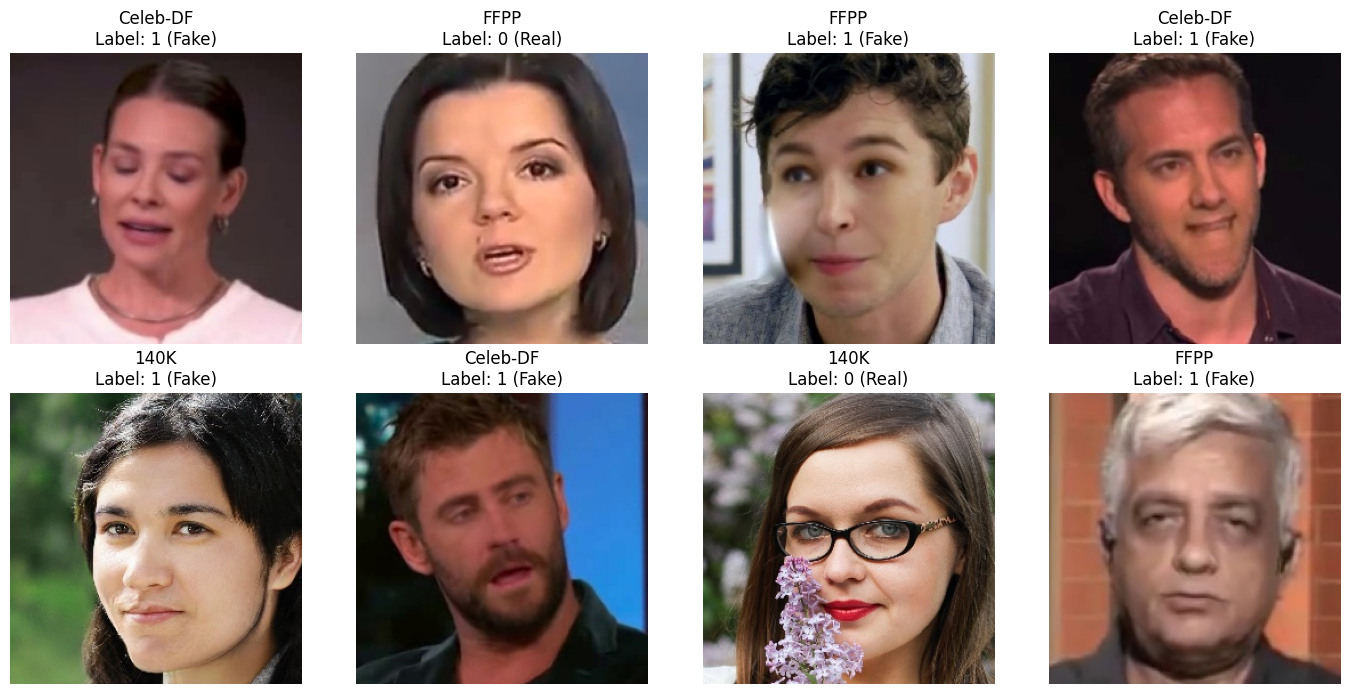

In [9]:

from collections import Counter
from pathlib import Path
import random
import matplotlib.pyplot as plt
from PIL import Image

# Check class counts separately for each dataset source.
def identify_source(path):
    p = str(path).lower()

    if "celeb_v2" in p or "celebdf" in p:
        return "Celeb-DF"
    elif "dataset_processed_split" in p or "faceforensics" in p:
        return "FFPP"
    elif "real-vs-fake" in p or "140k-real-and-fake-faces" in p:
        return "140K"
    return "UNKNOWN"

for split_name, dataset in [
    ("TRAIN", train_dataset),
    ("VALIDATION", val_dataset),
    ("TEST", test_dataset),
]:
    print(f"\n--- {split_name} ---")
    counts = {}

    for path, label in zip(dataset.image_paths, dataset.labels):
        source = identify_source(path)
        counts[(source, label)] = counts.get((source, label), 0) + 1

    for source in ["Celeb-DF", "FFPP", "140K", "UNKNOWN"]:
        real_count = counts.get((source, 0), 0)
        fake_count = counts.get((source, 1), 0)
        if real_count or fake_count:
            print(
                f"{source}: Real(label 0)={real_count}, "
                f"Fake(label 1)={fake_count}"
            )

# Display random images with their assigned labels.
random.seed(42)
indices = random.sample(
    range(len(train_dataset)),
    min(8, len(train_dataset))
)

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, idx in zip(axes.flat, indices):
    path = train_dataset.image_paths[idx]
    label = train_dataset.labels[idx]

    # Open the original image without training augmentation.
    img = Image.open(path).convert("RGB")
    ax.imshow(img)
    ax.set_title(
        f"{identify_source(path)}\n"
        f"Label: {label} ({'Fake' if label == 1 else 'Real'})"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()


In [10]:

# Print example file paths with their assigned labels.
# This does not train the model or modify your datasets.

for source_name in ["Celeb-DF", "FFPP", "140K"]:
    print(f"\n--- {source_name} ---")

    shown = {0: 0, 1: 0}

    for path, label in zip(
        train_dataset.image_paths,
        train_dataset.labels
    ):
        if identify_source(path) != source_name:
            continue

        if shown[label] < 3:
            print(
                f"Label={label} "
                f"({'REAL' if label == 0 else 'FAKE'}): {path}"
            )
            shown[label] += 1

        if shown[0] >= 3 and shown[1] >= 3:
            break



--- Celeb-DF ---
Label=1 (FAKE): /kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2/Train/fake/id6_id17_0009_face_48058.jpg
Label=1 (FAKE): /kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2/Train/fake/id31_id37_0008_face_24235.jpg
Label=0 (REAL): /kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2/Train/real/id35_0009_face_15205.jpg
Label=1 (FAKE): /kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2/Train/fake/id11_id7_0006_face_1397.jpg
Label=0 (REAL): /kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2/Train/real/id8_0005_face_32552.jpg
Label=0 (REAL): /kaggle/input/datasets/pranabr0y/celebdf-v2image-dataset/Celeb_V2/Train/real/00184_face_10478.jpg

--- FFPP ---
Label=0 (REAL): /kaggle/input/datasets/gradientvoyager/faceforensics-c23-extracted-faces-100k/dataset_processed_split/train/Real/671_f141.jpg
Label=1 (FAKE): /kaggle/input/datasets/gradientvoyager/faceforensics-c23-extracted-faces-100k/dataset_processed

In [11]:
# [FIX] The final SpatialDeepfakeDetector is initialized once in the model setup cell below.
# This cell intentionally does not create a throwaway Xception instance.

In [12]:
# Input batch sanity check (model output is checked after the final model is initialized).
images, labels = next(iter(train_loader))
print(f"Batch images shape: {tuple(images.shape)} (expected [B, 3, 299, 299])")
print(f"Batch labels shape: {tuple(labels.shape)}; unique labels={labels.unique().tolist()}")
assert images.ndim == 4 and images.shape[1:] == (3, 299, 299)
assert set(labels.unique().tolist()).issubset({0, 1})

Batch images shape: (16, 3, 299, 299) (expected [B, 3, 299, 299])
Batch labels shape: (16,); unique labels=[0, 1]


In [13]:
# [FIX] Reuse the batch loaded in the preceding sanity-check cell; avoid a second disk read.
print("Using the same sanity-check batch for visualization and model-shape checks.")

Using the same sanity-check batch for visualization and model-shape checks.


In [14]:
import torchvision
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn
import timm

In [15]:
def imshow(inp, title=None):
    """Imshow for Tensor."""
    inp = inp.numpy().transpose((1, 2, 0))
    
    # Un-normalize 
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = std * inp + mean
    inp = np.clip(inp, 0, 1)
    
    plt.figure(figsize=(12, 8))
    plt.imshow(inp)
    if title is not None:
        plt.title(title)
    plt.axis('off')
    plt.show()

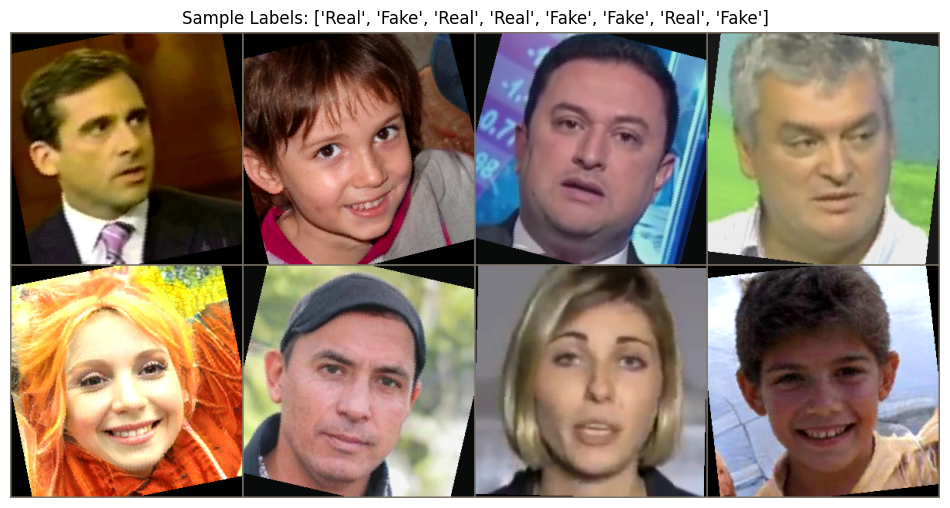

In [16]:
# Grab a single batch
images, labels = next(iter(train_loader))

num_images_to_show = 8
images_to_show = images[:num_images_to_show]
labels_to_show = labels[:num_images_to_show]

out = torchvision.utils.make_grid(images_to_show, nrow=4)
label_mapping = {0: "Real", 1: "Fake"}
titles = [label_mapping[int(label.item())] for label in labels_to_show]

imshow(out, title=f"Sample Labels: {titles}")

In [17]:
# Xception binary classifier with TWO logits (Real=0, Fake=1).
# CrossEntropyLoss and ART therefore use the same class-index label convention.
class SpatialDeepfakeDetector(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model('xception', pretrained=pretrained, num_classes=2)

    def forward(self, x):
        return self.backbone(x)


In [18]:
# Reproducibility and input/label sanity checks
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = True

assert len(train_dataset) > 0 and len(val_dataset) > 0 and len(test_dataset) > 0, "A dataset split is empty; inspect dataset discovery and class-folder names."
for split_name, ds in [('train', train_dataset), ('val', val_dataset), ('test', test_dataset)]:
    counts = {0: ds.labels.count(0), 1: ds.labels.count(1)}
    print(f"{split_name}: n={len(ds)}, Real(0)={counts[0]}, Fake(1)={counts[1]}")
    assert counts[0] > 0 and counts[1] > 0, f"{split_name} is missing a class."

# Split leakage check: exact file paths must not overlap across splits.
train_paths, val_paths, test_paths = map(lambda ds: set(os.path.realpath(p) for p in ds.image_paths),
                                         (train_dataset, val_dataset, test_dataset))
print(f"Path overlap counts: train/val={len(train_paths & val_paths)}, train/test={len(train_paths & test_paths)}, val/test={len(val_paths & test_paths)}")
assert not (train_paths & val_paths or train_paths & test_paths or val_paths & test_paths), "Exact file paths overlap between splits."
print("Note: exact-path checks do not detect duplicate image content stored under different filenames.")

train: n=72000, Real(0)=36000, Fake(1)=36000
val: n=24654, Real(0)=12327, Fake(1)=12327
test: n=23664, Real(0)=11832, Fake(1)=11832
Path overlap counts: train/val=0, train/test=0, val/test=0
Note: exact-path checks do not detect duplicate image content stored under different filenames.


In [19]:
# [FIX] Initialize the actual final model once; ART, optimizer, training, and evaluation all reference this object.
print("Loading the final pretrained Xception model...")
model = SpatialDeepfakeDetector(pretrained=True).to(device)
images_device = images.to(device)
with torch.no_grad():
    outputs = model(images_device)
print(f"Input shape: {tuple(images_device.shape)}; output shape: {tuple(outputs.shape)}")
assert outputs.shape == (images_device.shape[0], 2), "Expected two logits per image (Real=0, Fake=1)."
del images_device, outputs

Loading the final pretrained Xception model...


/usr/local/lib/python3.13/dist-packages/timm/models/_factory.py:175: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
Input shape: (16, 3, 299, 299); output shape: (16, 2)


In [20]:
import torch.optim as optim
from tqdm import tqdm
import copy
from torch.optim.lr_scheduler import ReduceLROnPlateau

In [21]:
# Two-class logits -> CrossEntropyLoss; labels are integer class indices (0=Real, 1=Fake).
criterion = nn.CrossEntropyLoss()


In [22]:
# Optimizer for the final model. Verify that the classifier/head parameter group is non-empty.
backbone_params, classifier_params = [], []
for name, param in model.named_parameters():
    if name.endswith('.fc.weight') or name.endswith('.fc.bias') or name in {'backbone.fc.weight','backbone.fc.bias'}:
        classifier_params.append(param)
    else:
        backbone_params.append(param)
if not classifier_params:
    # timm variants may expose the classifier under another name; use get_classifier() parameters.
    head_ids = {id(p) for p in model.backbone.get_classifier().parameters()}
    backbone_params = [p for p in model.parameters() if id(p) not in head_ids]
    classifier_params = [p for p in model.parameters() if id(p) in head_ids]
assert classifier_params, "Could not identify Xception classifier parameters."
optimizer = optim.AdamW([
    {'params': backbone_params, 'lr': 1e-5},
    {'params': classifier_params, 'lr': 1e-3},
], weight_decay=1e-4)
print(f"Optimizer parameter tensors: backbone={len(backbone_params)}, head={len(classifier_params)}")

Optimizer parameter tensors: backbone=154, head=2


In [23]:
# 3. Early Stopping Class
class EarlyStopping:
    def __init__(self, patience=5, min_delta=0, verbose=True):
        self.patience = patience
        self.min_delta = min_delta
        self.verbose = verbose
        self.counter = 0
        self.best_loss = float('inf')
        self.early_stop = False
        self.best_model_wts = None

    def __call__(self, val_loss, model):
        if val_loss < self.best_loss - self.min_delta:
            if self.verbose:
                print(f"Validation loss decreased ({self.best_loss:.4f} --> {val_loss:.4f}). Saving model weights...")
            self.best_loss = val_loss
            self.best_model_wts = copy.deepcopy(model.state_dict())
            self.counter = 0
        else:
            self.counter += 1
            print(f"EarlyStopping counter: {self.counter} out of {self.patience}")
            if self.counter >= self.patience:
                self.early_stop = True

In [24]:
# ART FGSM adversarial training. ART receives raw RGB [0,1]; wrapper normalizes to ImageNet space.
# The same final `model` object is wrapped by ART and updated by `optimizer`.
import time, csv, os, copy
from art.estimators.classification import PyTorchClassifier
from art.attacks.evasion import FastGradientMethod
from torch.optim.lr_scheduler import ReduceLROnPlateau

EPSILON = 8.0 / 255.0
ADV_LOSS_WEIGHT = 0.5
GRAD_CLIP_NORM = 1.0
EPOCHS = 5
PATIENCE = 3
RESUME_TRAINING = False  # Set True only when resuming from this run directory.
RUN_DIR = os.environ.get("XCEPTION_RUN_DIR", "xception_art_fgsm_run")
os.makedirs(RUN_DIR, exist_ok=True)
CHECKPOINT_PATH = os.path.join(RUN_DIR, "best_validation.pt")
RESUME_PATH = os.path.join(RUN_DIR, "resume_state.pt")
HISTORY_PATH = os.path.join(RUN_DIR, "history.csv")
if not RESUME_TRAINING and os.path.exists(RESUME_PATH):
    # Never silently overwrite an earlier run's resume state.
    import datetime
    RUN_DIR = RUN_DIR + "_" + datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
    os.makedirs(RUN_DIR, exist_ok=False)
    CHECKPOINT_PATH = os.path.join(RUN_DIR, "best_validation.pt")
    RESUME_PATH = os.path.join(RUN_DIR, "resume_state.pt")
    HISTORY_PATH = os.path.join(RUN_DIR, "history.csv")
    print(f"Existing run found; using a new output directory: {RUN_DIR}")

mean_t = torch.tensor([0.485, 0.456, 0.406], device=device).view(1,3,1,1)
std_t = torch.tensor([0.229, 0.224, 0.225], device=device).view(1,3,1,1)
def normalize_raw(x):
    return (x - mean_t) / std_t

class ARTInputWrapper(nn.Module):
    """ART attack inputs are raw RGB [0,1]; the model expects ImageNet-normalized tensors."""
    def __init__(self, base_model):
        super().__init__(); self.base_model = base_model
    def forward(self, x):
        return self.base_model(normalize_raw(x))

art_model = ARTInputWrapper(model).to(device)
art_classifier = PyTorchClassifier(
    model=art_model, loss=criterion, optimizer=optimizer,
    input_shape=(3, 299, 299), nb_classes=2, clip_values=(0.0, 1.0),
    device_type="gpu" if device.type == "cuda" else "cpu")
fgsm = FastGradientMethod(estimator=art_classifier, eps=EPSILON, targeted=False)

# Sanity checks: output shape, nonzero gradients, optimizer ownership, and FGSM budget.
xb, yb = next(iter(train_loader)); xb, yb = xb.to(device), yb.to(device).long()
assert model(xb).shape == (xb.shape[0], 2)
optimizer.zero_grad(set_to_none=True)
criterion(model(xb), yb).backward()
grad_norm = sum(float(p.grad.detach().norm()) for p in model.parameters() if p.grad is not None)
opt_ids = {id(p) for group in optimizer.param_groups for p in group['params']}
assert grad_norm > 0, "No nonzero gradients detected."
assert any(p.requires_grad and id(p) in opt_ids for p in model.parameters()), "Optimizer is disconnected from model parameters."
optimizer.zero_grad(set_to_none=True)
print(f"Diagnostics passed: output={tuple(model(xb).shape)}, gradient-norm sum={grad_norm:.4g}")

# Timing-only benchmark: no optimizer.step(); restore all model state so BatchNorm statistics stay unchanged.
bench_model_state = copy.deepcopy(model.state_dict())
was_training = model.training
bench_inputs, bench_labels = next(iter(train_loader))
bench_inputs = bench_inputs.to(device, non_blocking=True); bench_labels = bench_labels.to(device).long()
model.eval()  # attack generation must not update BatchNorm running statistics
bench_raw = (bench_inputs * std_t + mean_t).clamp(0, 1)
t0 = time.time()
bench_adv_np = fgsm.generate(x=bench_raw.detach().cpu().numpy(), y=bench_labels.detach().cpu().numpy())
bench_adv_raw = torch.as_tensor(bench_adv_np, dtype=bench_inputs.dtype, device=device).clamp(0,1)
bench_adv_inputs = normalize_raw(bench_adv_raw)
model.train()
optimizer.zero_grad(set_to_none=True)
# sequential backward passes approximate the actual memory-conscious training step
clean_logits = model(bench_inputs); clean_loss = criterion(clean_logits, bench_labels)

((1.0-ADV_LOSS_WEIGHT)*clean_loss).backward()
del clean_logits, clean_loss
adv_logits = model(bench_adv_inputs); adv_loss = criterion(adv_logits, bench_labels)
(ADV_LOSS_WEIGHT*adv_loss).backward(); del adv_logits, adv_loss
benchmark_seconds = time.time() - t0
model.load_state_dict(bench_model_state); model.train(was_training)
optimizer.zero_grad(set_to_none=True)
del bench_model_state, bench_inputs, bench_labels, bench_raw, bench_adv_np, bench_adv_raw, bench_adv_inputs
if torch.cuda.is_available(): torch.cuda.empty_cache()
steps = len(train_loader)
print(f"Approximate epoch estimate: {steps} batches x {benchmark_seconds:.2f}s/batch = {steps*benchmark_seconds/60:.1f} min/epoch; "
      f"~{steps*benchmark_seconds*EPOCHS/3600:.1f} h for {EPOCHS} epochs. This is a rough estimate, not a guarantee.")

scheduler = ReduceLROnPlateau(optimizer, mode="min", patience=1, factor=0.2)
start_epoch, best_val_loss, bad_epochs, history = 0, float("inf"), 0, []
if RESUME_TRAINING:
    if not os.path.exists(RESUME_PATH):
        raise FileNotFoundError(f"RESUME_TRAINING=True but no resume checkpoint at {RESUME_PATH}")
    state = torch.load(RESUME_PATH, map_location=device)
    model.load_state_dict(state["model"]); optimizer.load_state_dict(state["optimizer"]); scheduler.load_state_dict(state["scheduler"])
    start_epoch = int(state["epoch"]) + 1
    best_val_loss = float(state.get("best_val_loss", float("inf")))
    bad_epochs = int(state.get("bad_epochs", 0)); history = state.get("history", [])
    print(f"Resuming at epoch {start_epoch+1} from {RESUME_PATH}")


for epoch in range(start_epoch, EPOCHS):
    epoch_start = time.time()
    model.train()

    running_loss, clean_correct, seen = 0.0, 0, 0
    grad_norm_sum, grad_norm_count = 0.0, 0

    for batch_idx, (inputs, labels) in enumerate(train_loader, 1):
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True).long()

        # Generate FGSM examples in raw pixel space.
        # Evaluation mode prevents BatchNorm statistics from changing
        # during attack generation.
        raw = (inputs * std_t + mean_t).clamp(0, 1)

        model.eval()
        adv_np = fgsm.generate(
            x=raw.detach().cpu().numpy(),
            y=labels.detach().cpu().numpy()
        )
        model.train()

        adv_raw = torch.as_tensor(
            adv_np, dtype=inputs.dtype, device=device
        ).clamp(0, 1)
        adv_inputs = normalize_raw(adv_raw)

        optimizer.zero_grad(set_to_none=True)

        # ----- Clean loss -----
        clean_logits = model(inputs)
        clean_loss = criterion(clean_logits, labels)

        if not torch.isfinite(clean_loss).item():
            raise FloatingPointError(
                f"Non-finite clean loss at epoch {epoch + 1}, "
                f"batch {batch_idx}"
            )

        clean_correct += (
            clean_logits.detach().argmax(1) == labels
        ).sum().item()

        clean_loss_value = float(clean_loss.detach())

        # Backpropagate weighted clean loss.
        ((1.0 - ADV_LOSS_WEIGHT) * clean_loss).backward()
        del clean_logits, clean_loss

        # ----- Adversarial loss -----
        adv_logits = model(adv_inputs)
        adv_loss = criterion(adv_logits, labels)

        if not torch.isfinite(adv_loss).item():
            raise FloatingPointError(
                f"Non-finite adversarial loss at epoch {epoch + 1}, "
                f"batch {batch_idx}"
            )

        adv_loss_value = float(adv_loss.detach())

        # Backpropagate weighted adversarial loss.
        (ADV_LOSS_WEIGHT * adv_loss).backward()

        # Check gradients before clipping.
        for name, param in model.named_parameters():
            if param.grad is not None:
                if not torch.isfinite(param.grad).all().item():
                    raise FloatingPointError(
                        f"Non-finite gradient in {name}, "
                        f"epoch {epoch + 1}, batch {batch_idx}"
                    )

        # Clip combined clean + adversarial gradients.
        grad_norm = torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=GRAD_CLIP_NORM,
            error_if_nonfinite=True
        )

        grad_norm_sum += float(grad_norm)
        grad_norm_count += 1

        # Update model parameters.
        optimizer.step()

        # Track combined loss and number of processed samples.
        batch_loss = (
            (1.0 - ADV_LOSS_WEIGHT) * clean_loss_value
            + ADV_LOSS_WEIGHT * adv_loss_value
        )

        running_loss += batch_loss * labels.size(0)
        seen += labels.size(0)

        if batch_idx % 25 == 0 or batch_idx == len(train_loader):
            elapsed = time.time() - epoch_start
            print(
                f"Epoch {epoch + 1}/{EPOCHS} "
                f"batch {batch_idx}/{len(train_loader)} "
                f"loss={running_loss / max(seen, 1):.4f} "
                f"clean-train-acc="
                f"{100 * clean_correct / max(seen, 1):.2f}% "
                f"grad-norm={float(grad_norm):.4f} "
                f"elapsed={elapsed / 60:.1f} min"
            )

        del raw, adv_np, adv_raw, adv_inputs, adv_logits, adv_loss

    train_loss = running_loss / max(seen, 1)
    train_acc = clean_correct / max(seen, 1)
    mean_grad_norm = grad_norm_sum / max(grad_norm_count, 1)

    # ----- Clean validation -----
    model.eval()
    val_loss_sum, val_correct, val_seen = 0.0, 0, 0

    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True).long()

            logits = model(inputs)
            val_loss_sum += (
                float(criterion(logits, labels)) * labels.size(0)
            )
            val_correct += (
                logits.argmax(1) == labels
            ).sum().item()
            val_seen += labels.size(0)

            del logits

    val_loss = val_loss_sum / max(val_seen, 1)
    val_acc = val_correct / max(val_seen, 1)

    scheduler.step(val_loss)
    elapsed = time.time() - epoch_start

    row = {
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "clean_train_accuracy": train_acc,
        "val_loss": val_loss,
        "clean_val_accuracy": val_acc,
        "learning_rate": optimizer.param_groups[0]["lr"],
        "mean_grad_norm": mean_grad_norm,
        "elapsed_seconds": elapsed
    }
    history.append(row)

    print(
        f"Epoch {epoch + 1}: "
        f"train_loss={train_loss:.4f}, "
        f"clean_train_acc={train_acc:.4f}, "
        f"val_loss={val_loss:.4f}, "
        f"clean_val_acc={val_acc:.4f}, "
        f"mean_grad_norm={mean_grad_norm:.4f}, "
        f"elapsed={elapsed / 60:.1f} min"
    )

    # Save the best checkpoint based on clean validation loss.
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        bad_epochs = 0

        torch.save(
            {
                "model": model.state_dict(),
                "epoch": epoch,
                "best_val_loss": best_val_loss
            },
            CHECKPOINT_PATH
        )
        print(f"Saved best validation checkpoint: {CHECKPOINT_PATH}")
    else:
        bad_epochs += 1

    # Save resumable training state after every epoch.
    torch.save(
        {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scheduler": scheduler.state_dict(),
            "epoch": epoch,
            "best_val_loss": best_val_loss,
            "bad_epochs": bad_epochs,
            "history": history
        },
        RESUME_PATH
    )

    with open(HISTORY_PATH, "w", newline="") as f:
        writer = csv.DictWriter(
            f, fieldnames=list(history[0].keys())
        )
        writer.writeheader()
        writer.writerows(history)

    if bad_epochs >= PATIENCE:
        print("Early stopping based on clean validation loss.")
        break

if not os.path.exists(CHECKPOINT_PATH):
    raise RuntimeError(
        "No best-validation checkpoint was created; "
        "training did not complete an epoch."
    )

best_state = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(best_state["model"])
model.eval()

print(
    f"Restored best checkpoint from epoch "
    f"{best_state['epoch'] + 1}; "
    f"val loss={best_state['best_val_loss']:.4f}"
)


Diagnostics passed: output=(16, 2), gradient-norm sum=10.74
Approximate epoch estimate: 4500 batches x 1.15s/batch = 86.1 min/epoch; ~7.2 h for 5 epochs. This is a rough estimate, not a guarantee.
Epoch 1/5 batch 25/4500 loss=0.7498 clean-train-acc=47.75% grad-norm=3.3134 elapsed=0.7 min
Epoch 1/5 batch 50/4500 loss=0.7410 clean-train-acc=50.88% grad-norm=1.1387 elapsed=1.4 min
Epoch 1/5 batch 75/4500 loss=0.7415 clean-train-acc=50.25% grad-norm=3.6357 elapsed=2.2 min
Epoch 1/5 batch 100/4500 loss=0.7401 clean-train-acc=51.44% grad-norm=1.0175 elapsed=2.9 min
Epoch 1/5 batch 125/4500 loss=0.7393 clean-train-acc=50.55% grad-norm=3.4510 elapsed=3.5 min
Epoch 1/5 batch 150/4500 loss=0.7389 clean-train-acc=51.04% grad-norm=1.6740 elapsed=4.2 min
Epoch 1/5 batch 175/4500 loss=0.7372 clean-train-acc=51.07% grad-norm=1.7598 elapsed=5.0 min
Epoch 1/5 batch 200/4500 loss=0.7341 clean-train-acc=51.00% grad-norm=1.1463 elapsed=5.7 min
Epoch 1/5 batch 225/4500 loss=0.7310 clean-train-acc=51.00% gr

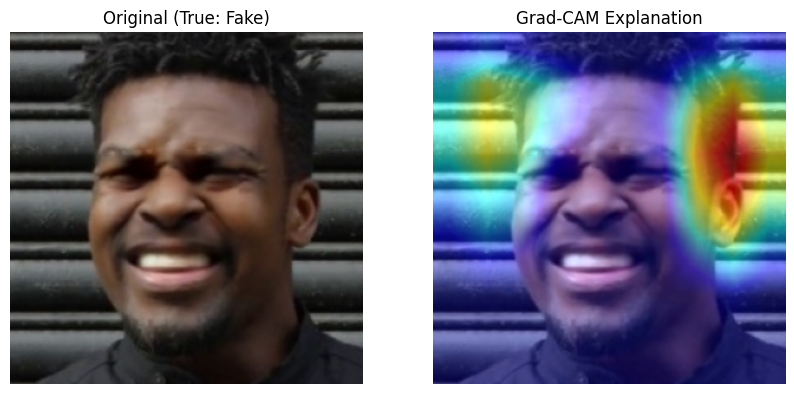

In [25]:
import torch.nn.functional as F

# Unfreeze layers for GradCAM
for param in model.backbone.parameters():
    param.requires_grad = True

class GradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        
        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor, target_class=None):
        model_output = self.model(input_tensor)
        if target_class is None:
            target_class = int(model_output.detach().argmax(dim=1).item())
        score = model_output[:, target_class].sum()
        self.model.zero_grad(set_to_none=True)
        score.backward()
        
        pooled_gradients = torch.mean(self.gradients, dim=[0, 2, 3])
        activations = self.activations.detach()[0]
        for i in range(activations.shape[0]):
            activations[i, :, :] *= pooled_gradients[i]
            
        heatmap = torch.mean(activations, dim=0).squeeze().cpu().numpy()
        heatmap = np.maximum(heatmap, 0)
        if np.max(heatmap) != 0:
            heatmap /= np.max(heatmap)
        return heatmap

# Target the deepest convolutional layer
target_layer = model.backbone.conv4 
cam = GradCAM(model, target_layer)

model.eval() 
sample_img, sample_label = next(iter(test_loader)) # Use test loader for unseen data
sample_img = sample_img[0:1].to(device)

heatmap = cam.generate_heatmap(sample_img)

# --- VISUALIZATION ---
inv_normalize = transforms.Normalize(
    mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
    std=[1/0.229, 1/0.224, 1/0.225]
)
disp_img = inv_normalize(sample_img[0].cpu())
disp_img = disp_img.permute(1, 2, 0).numpy()
disp_img = np.clip(disp_img, 0, 1)

heatmap_resized = cv2.resize(heatmap, (299, 299))
heatmap_colored = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
heatmap_colored = np.float32(heatmap_colored) / 255
heatmap_colored = heatmap_colored[..., ::-1] 

overlay = heatmap_colored * 0.5 + disp_img
overlay = np.clip(overlay, 0, 1)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(disp_img)
axes[0].set_title(f"Original (True: {'Fake' if sample_label[0].item() == 1 else 'Real'})")
axes[0].axis('off')

axes[1].imshow(overlay)
axes[1].set_title("Grad-CAM Explanation")
axes[1].axis('off')

plt.show()

## Run, outputs, and resume notes

- Run every cell from the top in a Kaggle GPU session. Internet access may be needed to install ART and download pretrained Xception weights.
- Keep the full dataset attached; this notebook does not silently subset it. The timing estimate is a single-batch approximation and can under/overestimate a full epoch.
- Outputs are written to `xception_art_fgsm_run/` (or a timestamped sibling if a prior resume state exists): best validation checkpoint, resumable model/optimizer/scheduler state, CSV history, and final weights.
- To resume, set `RESUME_TRAINING = True` and set `XCEPTION_RUN_DIR` to the exact existing run directory before running the training cell.
- A complete GPU training run was not performed during notebook preparation; verify one benchmark batch and inspect the runtime estimate before starting the full run.

## Final evaluation (test set used only here)

The model is restored from the best validation-loss checkpoint. Clean metrics use the untouched test images. FGSM metrics generate adversarial test inputs on the fly at raw-pixel epsilon `8/255`; these images are not used for training and no optimizer step occurs during evaluation. Outputs and history are saved under the run directory printed above.

Clean test: 100%|██████████| 1479/1479 [40:09<00:00,  1.63s/it]



--- CLEAN ---
Loss: 0.6924
Accuracy: 0.5905
Macro F1: 0.5166
ROC-AUC: 0.7607
              precision    recall  f1-score   support

        Real       0.91      0.20      0.33     11832
        Fake       0.55      0.98      0.71     11832

    accuracy                           0.59     23664
   macro avg       0.73      0.59      0.52     23664
weighted avg       0.73      0.59      0.52     23664



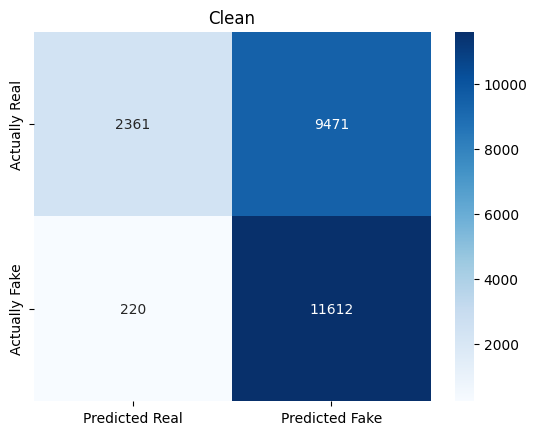

Test eps=0.00392156862745098: 100%|██████████| 1479/1479 [18:36<00:00,  1.32it/s]


--- FGSM eps=0.003922 ---
Loss: 0.6959
Accuracy: 0.3065
Macro F1: 0.2384
ROC-AUC: 0.1805
              precision    recall  f1-score   support

        Real       0.02      0.01      0.01     11832
        Fake       0.38      0.61      0.47     11832

    accuracy                           0.31     23664
   macro avg       0.20      0.31      0.24     23664
weighted avg       0.20      0.31      0.24     23664



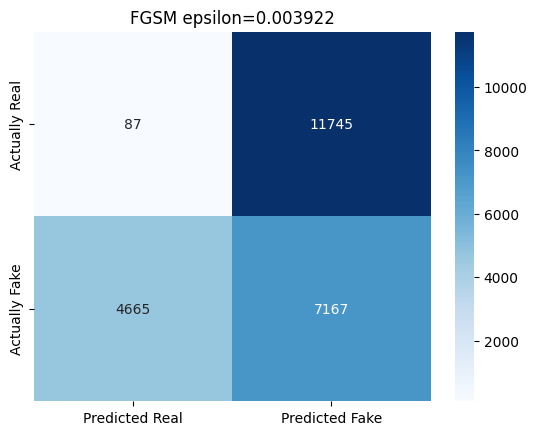

Test eps=0.01568627450980392: 100%|██████████| 1479/1479 [18:36<00:00,  1.32it/s]


--- FGSM eps=0.015686 ---
Loss: 0.6945
Accuracy: 0.3863
Macro F1: 0.2812
ROC-AUC: 0.2756
              precision    recall  f1-score   support

        Real       0.02      0.00      0.01     11832
        Fake       0.44      0.77      0.56     11832

    accuracy                           0.39     23664
   macro avg       0.23      0.39      0.28     23664
weighted avg       0.23      0.39      0.28     23664



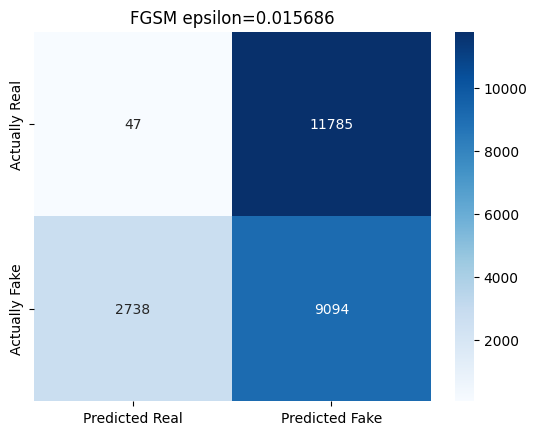

Test eps=0.03137254901960784: 100%|██████████| 1479/1479 [18:32<00:00,  1.33it/s]


--- FGSM eps=0.031373 ---
Loss: 0.6937
Accuracy: 0.4433
Macro F1: 0.3103
ROC-AUC: 0.3831
              precision    recall  f1-score   support

        Real       0.03      0.00      0.01     11832
        Fake       0.47      0.88      0.61     11832

    accuracy                           0.44     23664
   macro avg       0.25      0.44      0.31     23664
weighted avg       0.25      0.44      0.31     23664



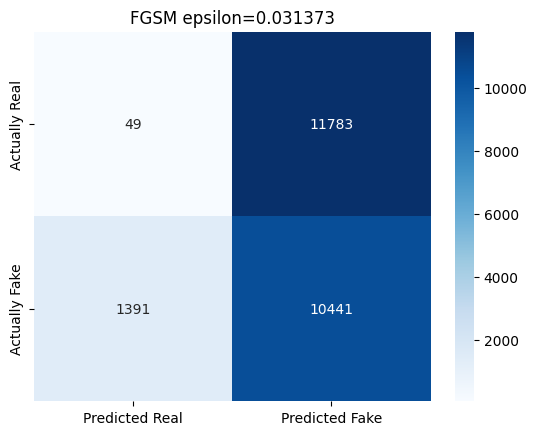

In [26]:

from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    f1_score, roc_auc_score
)
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import torch

# Restore the best validation-loss checkpoint.
best_state = torch.load(CHECKPOINT_PATH, map_location=device)
model.load_state_dict(best_state["model"])
model.eval()

# Use the same ART raw-pixel wrapper as training.
art_model = ARTInputWrapper(model).to(device)
art_classifier = PyTorchClassifier(
    model=art_model,
    loss=criterion,
    optimizer=optimizer,
    input_shape=(3, 299, 299),
    nb_classes=2,
    clip_values=(0.0, 1.0),
    device_type="gpu" if device.type == "cuda" else "cpu"
)

def evaluate_test(epsilon=None):
    is_adv = epsilon is not None
    attack = None

    if is_adv:
        attack = FastGradientMethod(
            estimator=art_classifier,
            eps=float(epsilon),
            targeted=False
        )

    y_true, y_pred, y_score = [], [], []
    loss_sum, sample_count = 0.0, 0

    model.eval()

    for inputs, labels in tqdm(
        test_loader,
        desc=f"Test eps={epsilon}" if is_adv else "Clean test"
    ):
        inputs = inputs.to(device, non_blocking=True)
        labels = labels.to(device).long()

        if is_adv:
            raw = (inputs * std_t + mean_t).clamp(0, 1)
            adv_np = attack.generate(
                x=raw.detach().cpu().numpy(),
                y=labels.detach().cpu().numpy()
            )
            raw_adv = torch.as_tensor(
                adv_np, dtype=inputs.dtype, device=device
            ).clamp(0, 1)
            model_inputs = normalize_raw(raw_adv)
        else:
            model_inputs = inputs

        with torch.no_grad():
            logits = model(model_inputs)
            batch_loss = criterion(logits, labels)
            probabilities = torch.softmax(logits, dim=1)
            predictions = logits.argmax(dim=1)

        n = labels.size(0)
        loss_sum += batch_loss.item() * n
        sample_count += n
        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())
        y_score.extend(probabilities[:, 1].cpu().numpy())

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    y_score = np.asarray(y_score)

    assert len(y_true) == len(test_dataset)

    metrics = {
        "loss": loss_sum / sample_count,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "roc_auc": roc_auc_score(y_true, y_score),
    }

    print(f"\n--- {'CLEAN' if not is_adv else f'FGSM eps={epsilon:.6f}'} ---")
    print(f"Loss: {metrics['loss']:.4f}")
    print(f"Accuracy: {metrics['accuracy']:.4f}")
    print(f"Macro F1: {metrics['macro_f1']:.4f}")
    print(f"ROC-AUC: {metrics['roc_auc']:.4f}")
    print(classification_report(
        y_true, y_pred,
        labels=[0, 1],
        target_names=["Real", "Fake"],
        zero_division=0
    ))

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=["Predicted Real", "Predicted Fake"],
        yticklabels=["Actually Real", "Actually Fake"]
    )
    plt.title("Clean" if not is_adv else f"FGSM epsilon={epsilon:.6f}")
    plt.show()

    return y_true, y_pred, y_score, metrics

# Clean test evaluation.
clean_result = evaluate_test()

# FGSM evaluations at 1/255, 4/255, and 8/255.
fgsm_results = {}
for eps in [1/255, 4/255, 8/255]:
    fgsm_results[eps] = evaluate_test(epsilon=eps)
